## Imports e função show

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def show(images, titles, cmap='gray', tamanho = 4):
  n = len(images)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(images[i], cmap=cmap)
    plt.title(titles[i])
    plt.axis('off')
  plt.show()

## Função de segmentação

In [3]:
def segmentar(img, area_min=500):
  img_blur = cv2.GaussianBlur(img, (5, 5), 0)
  img_adapt = cv2.adaptiveThreshold(img_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 101, -10)

  contourns, _ = cv2.findContours(img_adapt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  contourns = [c for c in contourns if cv2.contourArea(c) > area_min]

  semantica = np.zeros_like(img)
  cv2.drawContours(semantica, contourns, -1, 255, -1)

  n, instancia = cv2.connectedComponents(semantica)
  print('Quantidade de objetos:', n - 1)

  return semantica, instancia

In [4]:
def comparar(img, semantica, instancia, nome='objeto', tamanho=5):
  plt.figure(figsize=(tamanho*3, tamanho))

  plt.subplot(1, 3, 1)
  plt.imshow(img, cmap='gray')
  plt.title('Entrada')
  plt.axis('off')

  plt.subplot(1, 3, 2)
  plt.imshow(semantica, cmap='gray')
  plt.title(f'Semântica (1 classe: {nome})')
  plt.axis('off')

  plt.subplot(1, 3, 3)
  plt.imshow(instancia, cmap='nipy_spectral')
  plt.title(f'Instância (1 cor por {nome})')
  plt.axis('off')

  plt.show()

## Imagem 1 – Moedas (`data.coins`)

Quantidade de objetos: 24


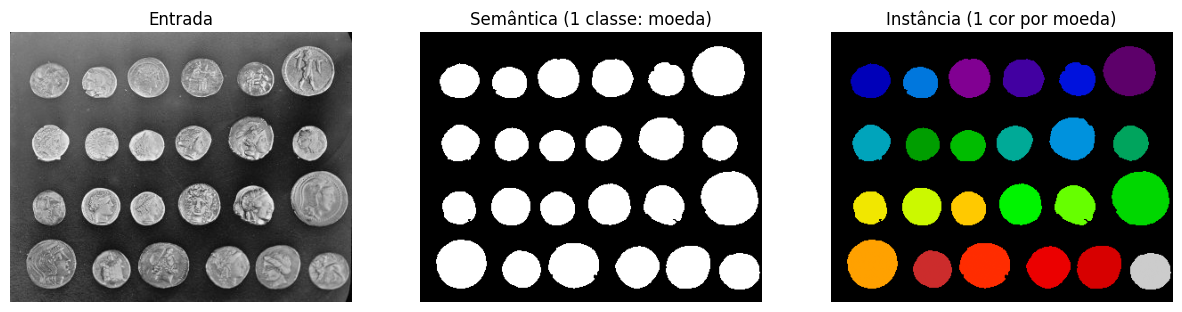

In [5]:
coins = data.coins()

coins_sem, coins_inst = segmentar(coins, area_min=500)
comparar(coins, coins_sem, coins_inst, 'moeda')

## Imagem 2 – Campo profundo do Hubble (`data.hubble_deep_field`)

A imagem é colorida, então é convertida para tons de cinza antes. Como as galáxias/estrelas são bem menores que as moedas, a área mínima foi reduzida para 100.

Quantidade de objetos: 106


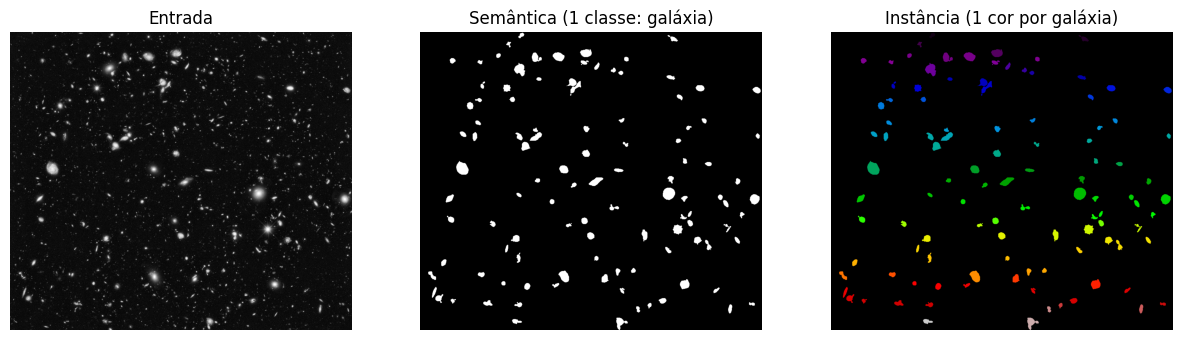

In [6]:
hubble = data.hubble_deep_field()
hubble = cv2.cvtColor(hubble, cv2.COLOR_RGB2GRAY)

hubble_sem, hubble_inst = segmentar(hubble, area_min=100)
comparar(hubble, hubble_sem, hubble_inst, 'galáxia')

## Análise

**Houve diferença sim.**

* **Moedas:** os objetos são grandes, têm tamanho parecido, estão bem separados e o fundo é uniforme. Por isso a segmentação funciona bem: cada moeda vira exatamente uma instância (24 objetos = 24 moedas).
* **Hubble:** os objetos têm tamanhos e brilhos muito diferentes, e o fundo tem ruído. Com os mesmos parâmetros, as estrelas pequenas ou fracas somem (pelo filtro de área ou pelo limiar), e galáxias que se encostam viram uma instância só. Foram encontrados 106 objetos, bem menos do que os pontos visíveis na imagem. Então a semântica até mostra "onde há objeto", mas a separação por instância fica pior.

**Conclusão:** essa abordagem simples (limiar + contornos + componentes conectados) funciona bem quando os objetos são parecidos e separados, como as moedas. Em cenas mais complexas, os parâmetros precisam ser ajustados para cada imagem, e objetos que se tocam acabam sendo agrupados.